# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

--- First 5 Rows of the Dataset ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



--- Summary Statistics ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,9404,9404.000000,9404.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,...,9404,7069.000000,1011.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404,9404
unique,1,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,713
top,Resort Hotel,NaN,NaN,NaN,October,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-11-15
freq,9404,NaN,NaN,NaN,1610,NaN,NaN,NaN,NaN,NaN,...,8816,NaN,NaN,NaN,7031,NaN,NaN,NaN,7069,124
mean,NaN,0.248299,79.326244,2015.156104,NaN,37.026584,15.515313,1.155040,3.078690,1.864738,...,NaN,200.990946,219.550940,1.019034,NaN,86.843614,0.144938,0.613143,NaN,NaN
std,NaN,0.432049,87.584146,0.443661,NaN,11.083421,9.025545,1.124304,2.379227,1.198565,...,NaN,80.330753,104.296474,10.137928,NaN,53.759940,0.353264,0.835930,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,9.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,8.000000,2015.000000,NaN,31.000000,7.000000,0.000000,1.000000,2.000000,...,NaN,156.000000,135.000000,0.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,48.000000,2015.000000,NaN,38.000000,16.000000,1.000000,3.000000,2.000000,...,NaN,240.000000,223.000000,0.000000,NaN,71.550000,0.000000,0.000000,NaN,NaN
75%,NaN,0.000000,118.000000,2015.000000,NaN,45.000000,23.000000,2.000000,5.000000,2.000000,...,NaN,241.000000,286.000000,0.000000,NaN,120.600000,0.000000,1.000000,NaN,NaN


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. Lead time has a very large range from 0 to 737 days which could possibly skew distance clustering models. Columns like lead time and adr have higher ranges while other columns like total_of_special_request or stays_in_weekend_nights are single digit ranges.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

Preprocessed data shape: (6415, 4)

First few rows of scaled data:


,lead_time,stays_in_week_nights,adr,total_of_special_requests
0,-0.850083,-0.976403,-0.384691,-0.864782
1,-0.762478,-0.976403,-0.384691,-0.864782
2,-0.747877,-0.565701,0.049053,0.282597
3,-0.952290,-0.565701,0.218780,-0.864782
4,-0.820882,-0.565701,0.143346,0.282597


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I selected lead_time, stays_in_week_nights, adr, and total_of_special_requests. Lead time is important for identifying planners and last-minute bookers. Stays in week nights is essential for differentiating business travelers. Adr measures transaction amount nightly. Total nof special requests shows engagement of specific needs by guests.

2. Guests who book with a higher lead time pay a higher adr and might make more specific demands. Guests who book last minute with a lower lead time might choose affordable rooms, low adr, will most likely have less special requests. Guests who stay on weekdays will have more moderate rates and also most likely have less special requests.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

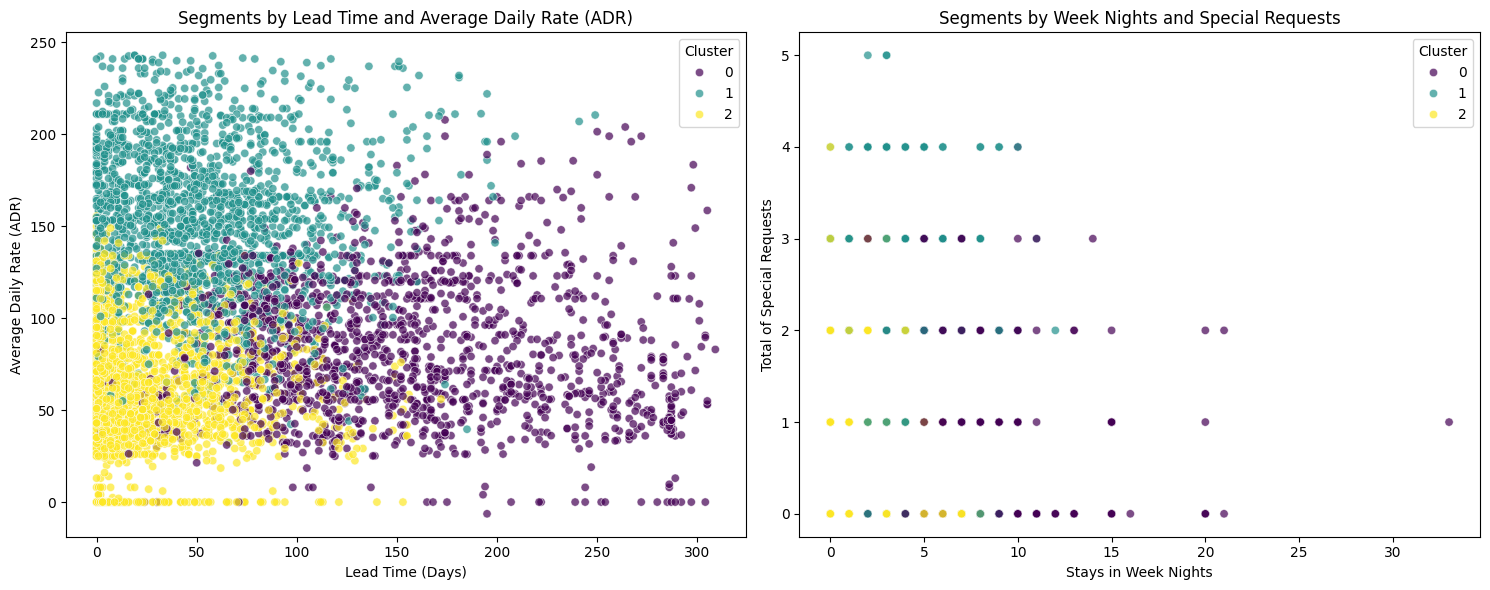


--- Cluster Averages (Centroids in Original Scale) ---


,lead_time,stays_in_week_nights,adr,total_of_special_requests
Cluster,,,,
0,153.885035,5.626204,81.866930,0.580604
1,54.097384,3.631298,152.180131,1.182171
2,24.029349,1.936650,60.993962,0.533644



--- Cluster Counts ---
Cluster
2    2794
1    2064
0    1557
Name: count, dtype: int64


### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I used k value 3. I decided that visual separation will give a clean visual to better understand lead time vs adr. The cluster is more balanced, more distrubuted rather than skewed.

2. Long stay travelers are cluster 0, (families, couples on vacation) They have the highest lead time, averaging bookings within months in advance. They stay significantly longer during the week compared to other groups. Cluster 1 is guests that npay a little more and are more engaged, they prefer a luxury stay and will often have special requests. They pay highest adr and have more special requests than other clusters. Cluster 2 is the spontaneous bookers that spend a little less. Their lead time is lower and they pay the lowest adr. They also have more brief stays.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

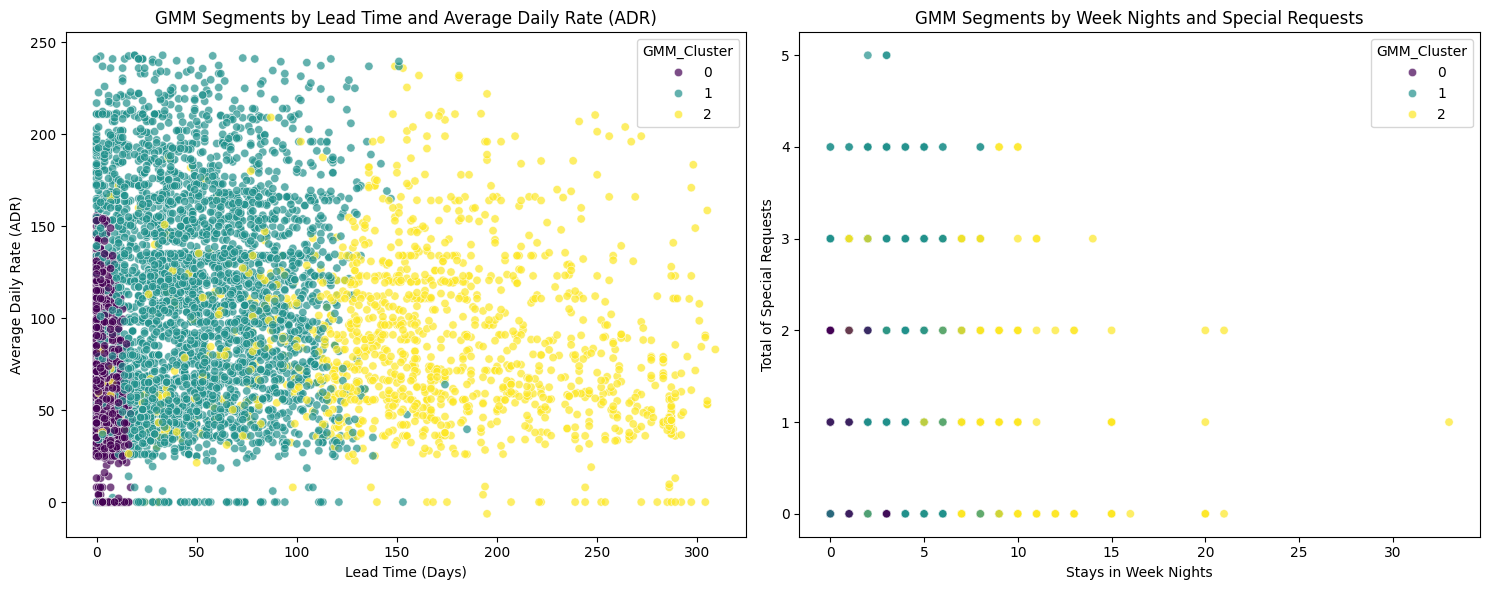


--- GMM Cluster Averages (Centroids in Original Scale) ---


,lead_time,stays_in_week_nights,adr,total_of_special_requests
GMM_Cluster,,,,
0,4.209666,1.240980,60.556542,0.500340
1,51.733537,3.408169,112.589950,0.888858
2,167.795843,5.625093,87.464692,0.668894



--- GMM Cluster Counts ---
GMM_Cluster
1    3599
0    1469
2    1347
Name: count, dtype: int64


### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. The results are a little different. GMM is a little cleaner.

2. GMM helps answer questions like how guests might have mixed/ transisitioning behaviors, how confident the business can be in targeting marketing spending, or where to expect overlaps between customer segments.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


=== K-Means Evaluation Metrics ===
WCSS (Inertia): 15274.0178
Silhouette Score: 0.2718
Davies-Bouldin Index: 1.3982

=== Gaussian Mixture Model (GMM) Evaluation Metrics ===
Equivalent WCSS (Inertia): 17851.5450
Silhouette Score: 0.1385
Davies-Bouldin Index: 1.7083


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. K-Means performed better across all three criteria. WCSS had a lower number than the GMM which is better. The silhouette score for K-Means was closer to 1 than GMM. Davies-Bouldin Index was lower in the K-means with indicates better clustering.

5.3. I would recommend K-Means because it is easier to explain and has clear groupings. It also has better performance metrics.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

=== K-Means Clusters (Sorted by Average Daily Rate / ADR) ===


,lead_time,stays_in_week_nights,adr,total_of_special_requests
Cluster,,,,
1,54.097384,3.631298,152.180131,1.182171
0,153.885035,5.626204,81.866930,0.580604
2,24.029349,1.936650,60.993962,0.533644



=== GMM Clusters (Sorted by Average Daily Rate / ADR) ===


,lead_time,stays_in_week_nights,adr,total_of_special_requests
GMM_Cluster,,,,
1,51.733537,3.408169,112.589950,0.888858
2,167.795843,5.625093,87.464692,0.668894
0,4.209666,1.240980,60.556542,0.500340


/tmp/ipykernel_759/2509985214.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=kmeans_sorted.reset_index(), x='Cluster', y='adr', ax=axes[0], palette='viridis')
/tmp/ipykernel_759/2509985214.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=gmm_sorted.reset_index(), x='GMM_Cluster', y='adr', ax=axes[1], palette='plasma')


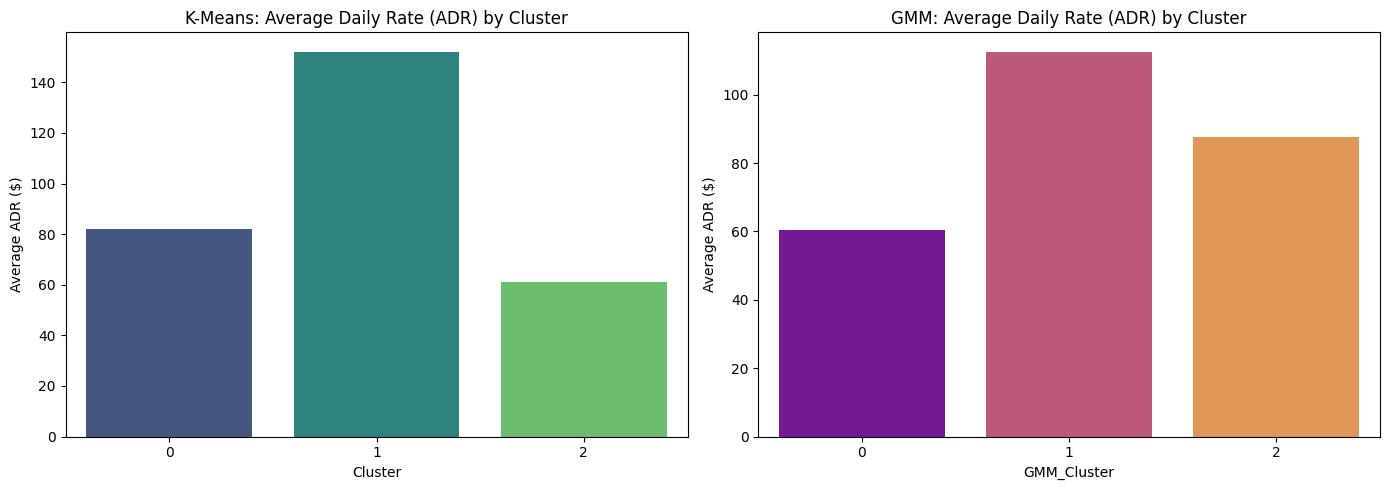

### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. Cluster 0 shows that the guest book months in advance and pay moderate rates compared to other clusters. They are long vacationers. Cluster 1 shows the guests that pay the highest adrs and have the highest number of special requests, they look for luxury. Cluster 2 are the last minute bookers with lower adrs and shorter stays.

2. For cluster 0, hotels can provide promotions for savings for those who are booking far in advance. They could focus on long-stay amenenties. For cluster 1, they could promote value-add packages that would provide complimentary credits for things like spas, fine dining, etc. For cluster 2, some promotions such as last-minute flash sales or discounts on bookings night of can bring in more clientel.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. Unsupervised learning has no target. Small changes in how the data is scaled to get the most accurate clustering requires a lot of trial and error.

2. I would use clustering when wanting to explore the data a little more. I want to find occuring patterns and structures within the data rather than predicting outcomes.

3. Clustering is like a helpful assitant who automatically groups hundreds of data points into piles without needing any manual labeling. This system groups thousands of guest accounts into clear personas so we can design targeted promotions toward those customers.

4. Understanding this helps me understand patterns between customer behavior and can help me in any future business ventures I have. Especially when it comes to target marketing.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"